In [6]:
# Libraries

%load_ext autoreload
%autoreload 2

from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from collections import Counter

PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import download_tiny_shakespeare, load_text

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
# Load Data 

data_path = download_tiny_shakespeare()

text = load_text(data_path)

print("Dataset downloaded successfully!")
print("File:", data_path)
print("File size:", round(data_path.stat().st_size / 1024, 2), "KB")

Dataset already exists.
Dataset downloaded successfully!
File: C:\Users\ASUS\Documents\Projects\Does Shakespeare need Attention\data\raw\tinyshakespeare.txt
File size: 1089.25 KB


In [8]:
# Statistics

total_chars = len(text)

total_lines = len(text.splitlines())

total_words = len(text.split())

unique_chars = sorted(set(text))

vocab_size = len(unique_chars)

print("Total characters:", total_chars)
print("Total lines:", total_lines)
print("Total words:", total_words)
print("Unique characters:", vocab_size)

print("\nVocabulary:")
print(repr("".join(unique_chars)))

Total characters: 1115394
Total lines: 40000
Total words: 202651
Unique characters: 65

Vocabulary:
"\n !$&',-.3:;?ABCDEFGHIJKLMNOPQRSTUVWXYZabcdefghijklmnopqrstuvwxyz"


In [9]:
# Character Frequency

char_counts = Counter(text)

char_freq = pd.DataFrame(
    char_counts.items(),
    columns=["Character", "Count"]
)

char_freq = char_freq.sort_values(
    "Count",
    ascending=False
).reset_index(drop=True)

char_freq["Percentage"] = (
    char_freq["Count"] / total_chars * 100
)

def display_char(char):
    if char == " ":
        return "[space]"

    if char == "\n":
        return "[newline]"

    if char == "\t":
        return "[tab]"

    return char

char_freq["Display"] = char_freq["Character"].apply(
    display_char
)

display(char_freq.head(30))

,Character,Count,Percentage,Display
0,,169892,15.231568,[space]
1,e,94611,8.482294,e
2,t,67009,6.007653,t
3,o,65798,5.899081,o
4,a,55507,4.976448,a
5,h,51310,4.600168,h
6,s,49696,4.455466,s
7,r,48889,4.383115,r
8,n,48529,4.350839,n
9,i,45537,4.082593,i


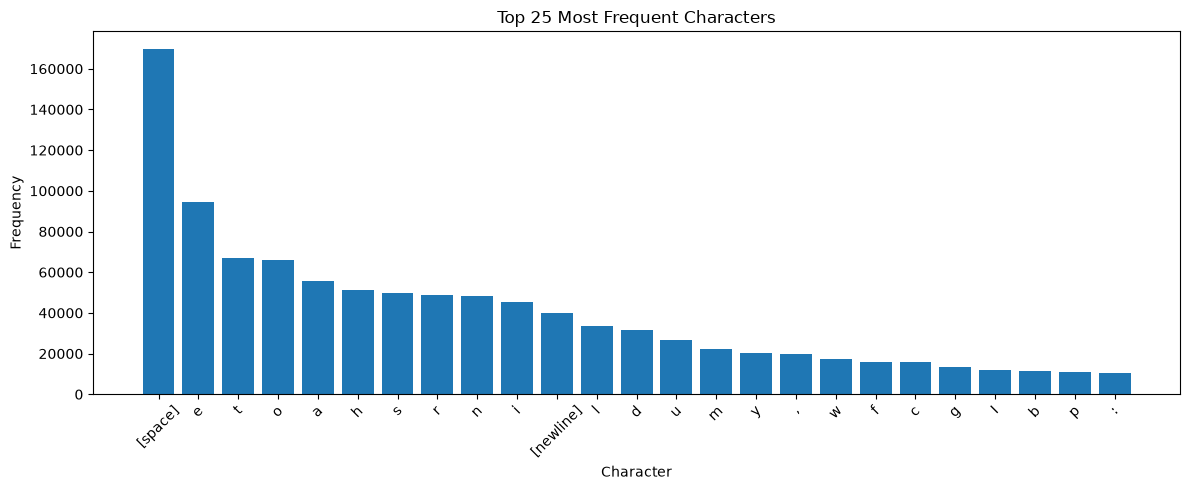

In [10]:
# Distribution

top_chars = char_freq.head(25)

plt.figure(figsize=(12, 5))

plt.bar(
    top_chars["Display"],
    top_chars["Count"]
)

plt.title("Top 25 Most Frequent Characters")
plt.xlabel("Character")
plt.ylabel("Frequency")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

Average line length: 26.88485
Maximum line length: 63
Minimum line length: 0


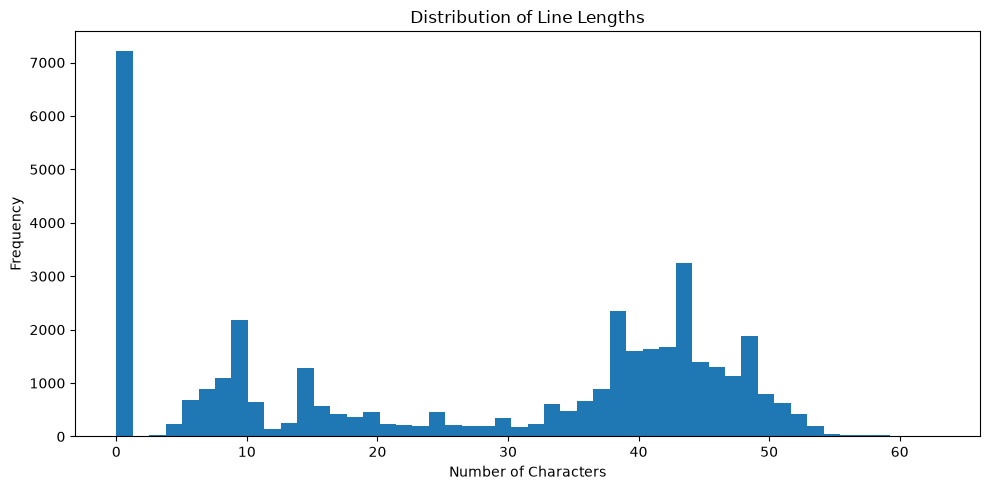

In [11]:
# Line Lengths

line_lengths = [
    len(line)
    for line in text.splitlines()
]

print("Average line length:", np.mean(line_lengths))
print("Maximum line length:", np.max(line_lengths))
print("Minimum line length:", np.min(line_lengths))

plt.figure(figsize=(10, 5))

plt.hist(
    line_lengths,
    bins=50
)

plt.title("Distribution of Line Lengths")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

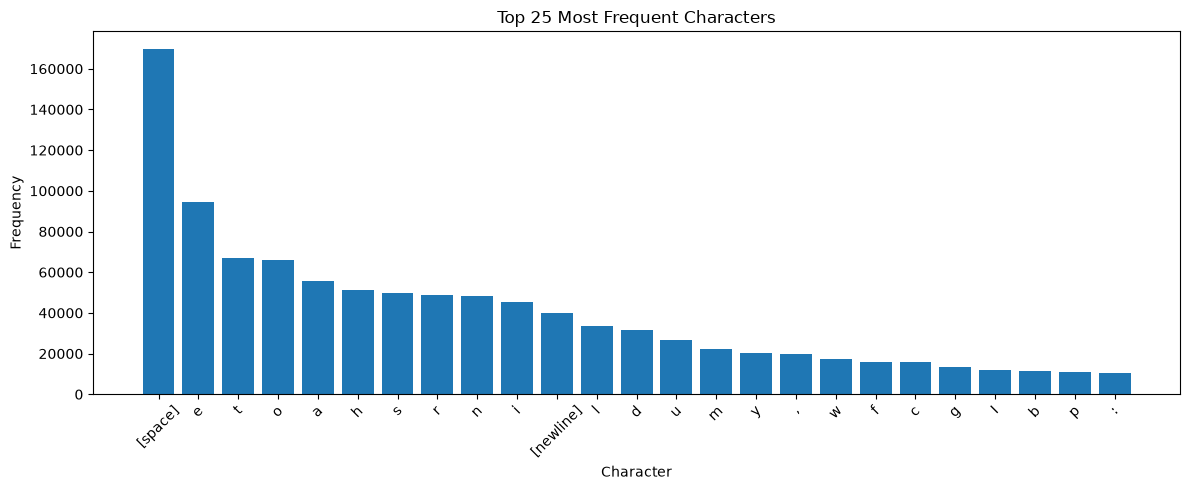

Exploration results saved successfully!


In [12]:
# Save

FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
RESULTS_DIR = PROJECT_ROOT / "reports" / "results"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


# Save dataset statistics
summary = pd.DataFrame([{
    "Total Characters": total_chars,
    "Total Lines": total_lines,
    "Total Words": total_words,
    "Vocabulary Size": vocab_size,
    "Average Line Length": np.mean(line_lengths),
    "Maximum Line Length": np.max(line_lengths)
}])

summary.to_csv(
    RESULTS_DIR / "dataset_summary.csv",
    index=False
)


# Save character frequencies
char_freq.to_csv(
    RESULTS_DIR / "character_frequency.csv",
    index=False
)


# Save character frequency figure
plt.figure(figsize=(12, 5))

plt.bar(
    top_chars["Display"],
    top_chars["Count"]
)

plt.title("Top 25 Most Frequent Characters")
plt.xlabel("Character")
plt.ylabel("Frequency")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(
    FIGURES_DIR / "character_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Exploration results saved successfully!")